# Final Examination: TranslateAI Ancient Character Recognition

Total Marks: 100

**Instructions:**
1. Enter your course email in the cell below.
2. Read the story and problem descriptions carefully.
3. Complete the code in cells containing `# YOUR CODE HERE`. Do not modify the test cells.
4. Run all cells sequentially to ensure your tests pass before submitting.

In [1]:
# Enter your course email here
student_email = "phitron@gmail.com" # Example: "your.name@university.edu"

---

## 📖 TranslateAI — Digitizing History

You have just been hired as a Machine Learning Engineer at **TranslateAI**, a startup working with international museums. Your first task is to build a neural network that can automatically classify ancient Japanese cursive texts.

We will use the **KMNIST** dataset — 28x28 grayscale images of 10 cursive characters: *o, ki, su, tsu, na, ha, ma, ya, re, wo*.

To ensure top performance, you must optimize your deep learning pipeline using **Batch Normalization** and **Advanced Optimizers (Adam)**.

---

## Question 1: Load, Explore, & Preprocess Data (20 Marks)

### 1.1 Download the Dataset (5 Marks)

We will use `torchvision.datasets.KMNIST` to download the dataset.

Run the cell below to download the training and test sets:

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Class names for KMNIST
class_names = ['o', 'ki', 'su', 'tsu', 'na', 'ha', 'ma', 'ya', 're', 'wo']

# Download KMNIST
full_train_dataset = torchvision.datasets.KMNIST(root='./data', train=True, download=True)
test_dataset_raw = torchvision.datasets.KMNIST(root='./data', train=False, download=True)

print(f"Training set size: {len(full_train_dataset)}")
print(f"Test set size: {len(test_dataset_raw)}")

Training set size: 60000
Test set size: 10000


### 1.2 Visualize Sample Grayscale Images (5 Marks)

Create a **2x5 subplot figure** (figsize 12x5) showing one sample image from **each of the 10 classes**.
- Title each subplot with its class name
- Turn off axis ticks
- Ensure you use `cmap='gray'` for visualization.

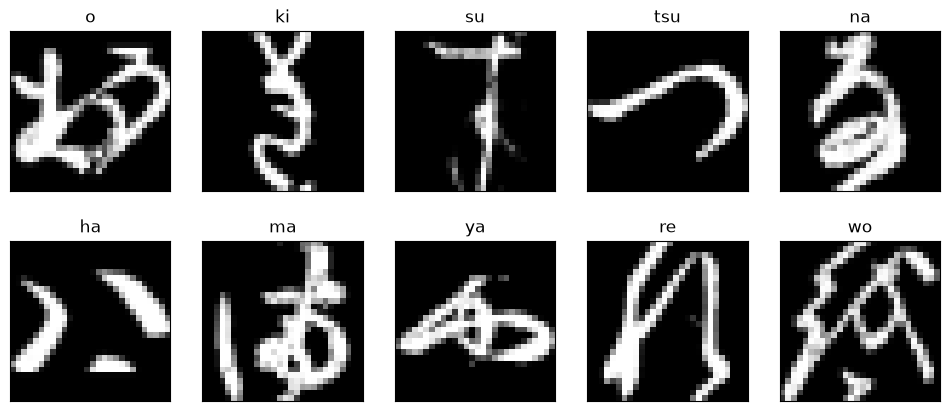

In [3]:
# data ke numpy array hishebe nilam
train_images_all = full_train_dataset.data.numpy()      # (60000, 28, 28)
train_labels_all = full_train_dataset.targets.numpy()   # (60000,)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

for i in range(10):
    index = list(train_labels_all).index(i)      # i number class er prothom chobir position
    axes[i].imshow(train_images_all[index], cmap='gray')
    axes[i].set_title(class_names[i])
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.show()

### 1.3 Data Scaling & Splitting (10 Marks)

**Your tasks:**
1. Extract images and labels from both train and test datasets as NumPy arrays. (Note: KMNIST images are 28x28)
2. Normalize the pixel values to the range [0, 1] by MinMax Scaling.
3. Split the training data into **train (50,000)** and **validation (10,000)** using `train_test_split` with `random_state=42`.
4. Convert all sets to PyTorch tensors — images as `float32`, labels as `long`.

**Required variables:** `X_train, X_val, X_test` (float32 tensors), `y_train, y_val, y_test` (long tensors)

In [4]:
# 1. train ar test dataset theke images ar labels numpy array e ana
train_images_all = full_train_dataset.data.numpy()       # (60000, 28, 28)
train_labels_all = full_train_dataset.targets.numpy()    # (60000,)
test_images_all = test_dataset_raw.data.numpy()          # (10000, 28, 28)
test_labels_all = test_dataset_raw.targets.numpy()       # (10000,)

# 2. MinMax Scaling (mod 18 Normalization): (x - x_min) / (x_max - x_min)
#    x_min, x_max shudhu train data theke nilam, test e same value ta use korbo
x_min = train_images_all.min()
x_max = train_images_all.max()

train_images_scaled = (train_images_all - x_min) / (x_max - x_min)
test_images_scaled = (test_images_all - x_min) / (x_max - x_min)

# 3. 60000 ke 50000 (train) + 10000 (validation) e bhag kora
X_train_np, X_val_np, y_train_np, y_val_np = train_test_split(train_images_scaled, train_labels_all, test_size=10000, random_state=42)

# 4. numpy theke tensor (image = float32, label = long)
X_train = torch.tensor(X_train_np, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)

X_val = torch.tensor(X_val_np, dtype=torch.float32)
y_val = torch.tensor(y_val_np, dtype=torch.long)

X_test = torch.tensor(test_images_scaled, dtype=torch.float32)
y_test = torch.tensor(test_labels_all, dtype=torch.long)

In [5]:
# --- TEST CELL (DO NOT MODIFY) ---
assert X_train.shape == (50000, 28, 28), f"Expected (50000, 28, 28), got {X_train.shape}"
assert X_val.shape == (10000, 28, 28)
assert X_train.dtype == torch.float32
assert y_train.dtype == torch.long
print("✅ Q1.3 Passed!")

✅ Q1.3 Passed!


---

## Question 2: Build PyTorch DataLoaders (15 Marks)

Create `TensorDataset` and `DataLoader` objects for train, validation, and test sets.

- **batch_size = 256**
- **shuffle = True** for training, **False** for validation and test

**Required variables:** `train_loader`, `val_loader`, `test_loader`

In [6]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

In [7]:
# --- TEST CELL (DO NOT MODIFY) ---
batch_X, batch_y = next(iter(train_loader))
assert batch_X.shape == (256, 28, 28)
assert batch_y.dtype == torch.long
print("✅ Q2 Passed!")

✅ Q2 Passed!


---

## Question 3: Deep Neural Network Architecture (25 Marks)

Create a class `TranslateAIClassifier` inheriting from `nn.Module`.

Use `nn.Sequential` with this architecture. Since the input is `28x28`, the flattened size is **784**.

| Layer | Description |
|-------|-------------|
| Flatten | Convert 28x28 → 784 |
| Linear | 784 → 512 |
| BatchNorm1d | Batch Normalization (512 features) |
| ReLU | Activation |
| Linear | 512 → 256 |
| BatchNorm1d | Batch Normalization (256 features) |
| ReLU | Activation |
| Linear | 256 → 128 |
| BatchNorm1d | Batch Normalization (128 features) |
| ReLU | Activation |
| Linear | 128 → 10 |

After defining the class, create an instance called `model` and print it.

In [8]:
torch.manual_seed(42)   # prothombar eki weight pete (mod 16/19)

class TranslateAIClassifier(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),                  # 28x28 -> 784
            nn.Linear(input_size, 512),
            nn.BatchNorm1d(512),           # Linear er pore, ReLU er age (mod 19)
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.Linear(128, num_classes)    # Output layer (Softmax debo na)
        )

    def forward(self, features):
        output = self.network(features)
        return output


model = TranslateAIClassifier(input_size=28*28, num_classes=10)
print(model)

TranslateAIClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=128, bias=True)
    (8): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [9]:
# --- TEST CELL (DO NOT MODIFY) ---
test_input = torch.randn(5, 28, 28)
test_output = model(test_input)
assert test_output.shape == (5, 10)
has_batchnorm = any(isinstance(m, nn.BatchNorm1d) for m in model.modules())
assert has_batchnorm, "Model must include BatchNorm1d layers"
print("✅ Q3 Passed!")

✅ Q3 Passed!


---

## Question 4: Advanced Training Pipeline (25 Marks)

### 4.1 Setup Optimizer and Loss (5 Marks)
- Loss function: `nn.CrossEntropyLoss`
- Optimizer: `optim.Adam` with `lr=0.001`
- Number of epochs: **15**

In [10]:
# GPU thakle GPU, nahole CPU (mod 16/19)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 15

Using device: cpu


### 4.2 PyTorch Training Pipeline (20 Marks)

Write the training loop for **15 epochs**.

For each epoch:
1. Set model to training mode (`model.train()`)
2. Train on `train_loader` (forward pass, calculate loss, backward pass, optimizer step)
3. Set model to evaluation mode (`model.eval()`)
4. Evaluate on `val_loader` and compute validation loss and accuracy.
5. Print: `Epoch {epoch+1}/{epochs} | Train Loss: {:.4f} | Val Loss: {:.4f}`

Store: `train_losses`, `val_losses` lists.

In [11]:
train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):

    # ---------- Training ----------
    model.train()          # BatchNorm ke batch er mean/std use korte bole
    running_loss = 0.0

    for batch_features, batch_labels in train_loader:
        # data ke GPU/CPU te pathano
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

        outputs = model(batch_features)               # forward pass

        loss = criterion(outputs, batch_labels)       # loss

        optimizer.zero_grad()
        loss.backward()                               # backward pass
        optimizer.step()                              # weight update

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)     # gor (average) loss

    # ---------- Validation ----------
    model.eval()           # BatchNorm ke training er jomano running mean/std use korte bole
    val_running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_features, batch_labels in val_loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

            outputs = model(batch_features)
            loss = criterion(outputs, batch_labels)
            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)      # sobcheye boro score er class
            total += batch_labels.shape[0]
            correct += (predicted == batch_labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}')

print(f'Final Validation Accuracy: {val_accuracies[-1]:.2f}%')

Epoch 1/15 | Train Loss: 0.3772 | Val Loss: 0.1805


Epoch 2/15 | Train Loss: 0.1322 | Val Loss: 0.1593


Epoch 3/15 | Train Loss: 0.0781 | Val Loss: 0.1511


Epoch 4/15 | Train Loss: 0.0518 | Val Loss: 0.1325


Epoch 5/15 | Train Loss: 0.0357 | Val Loss: 0.1307


...

Epoch 11/15 | Train Loss: 0.0132 | Val Loss: 0.1533


Epoch 12/15 | Train Loss: 0.0131 | Val Loss: 0.1518


Epoch 13/15 | Train Loss: 0.0112 | Val Loss: 0.1411


Epoch 14/15 | Train Loss: 0.0095 | Val Loss: 0.1433


Epoch 15/15 | Train Loss: 0.0072 | Val Loss: 0.1562
Final Validation Accuracy: 96.37%


In [12]:
# --- TEST CELL (DO NOT MODIFY) ---
assert len(train_losses) == 15, f"Expected 15 epochs, got {len(train_losses)}"
assert len(val_losses) == 15
print("✅ Q4.2 Passed!")

✅ Q4.2 Passed!


---

## Question 5: Evaluation & Analytics (15 Marks)

### 5.1 Test Evaluation (5 Marks)
Evaluate the model on the **test set**.
- Print the Test Accuracy.
- Collect Test dataset's all predictions into a list called `all_preds`.

In [13]:
model.eval()

all_preds = []
all_labels = []
correct = 0
total = 0

with torch.no_grad():
    for batch_features, batch_labels in test_loader:
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

        outputs = model(batch_features)

        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().tolist())          # list e joma rakhlam
        all_labels.extend(batch_labels.cpu().tolist())

        total += batch_labels.shape[0]
        correct += (predicted == batch_labels).sum().item()

test_accuracy = 100 * correct / total
print(f'Test Accuracy: {test_accuracy:.2f}%')

Test Accuracy: 91.55%


### 5.2 Plot Learning Curves (5 Marks)
Plot **Training Loss** and **Validation Loss** on the same figure across epochs. Include a legend and title.

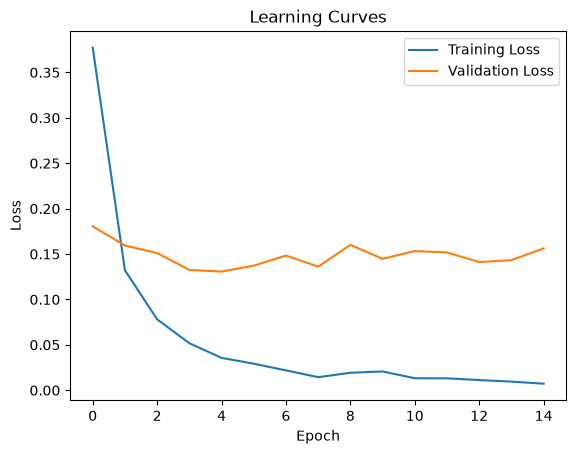

In [14]:
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Learning Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### 5.3 Confusion Matrix & Analysis (5 Marks)
1. Plot the confusion matrix using `ConfusionMatrixDisplay`.
2. Write a brief markdown explanation of which ancient character classes are most frequently confused by the model based on the matrix.

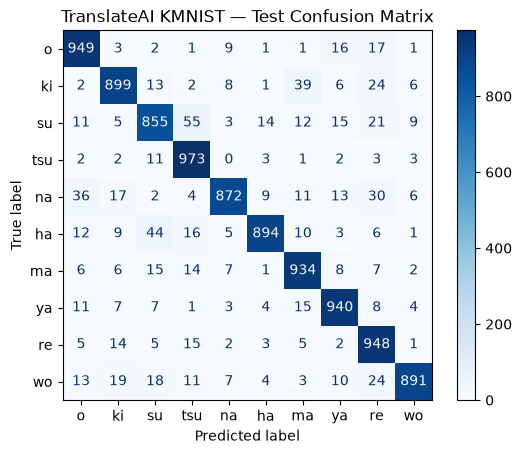

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues')

plt.title("TranslateAI KMNIST \u2014 Test Confusion Matrix")
plt.show()

*Double-click here to write your analysis*

**Your Analysis:**

**Most confused characters:** The model reaches about 91-92% test accuracy and most characters are recognised well (`tsu`, `re`, `ya`, `o` are the best). The biggest mistakes in my confusion matrix are:
- **su predicted as tsu** (about 55 images) - the most frequent confusion,
- **ha predicted as su** (about 44),
- **ki predicted as ma** (about 39),
- **na predicted as o** (about 36) and **na predicted as re** (about 30).

**Why?** These are *cursive* (hand-written, flowing) Japanese characters. `su` and `tsu` both have a curved loop/hook shape and look similar when written fast; `ki`, `ma`, `ha` share similar crossing strokes; and `na` has a long curved tail like `o` and `re`. At only 28x28 pixels, the small differences between these strokes almost disappear. Also, our model is a plain fully-connected network (MLP): it looks at each pixel separately and cannot "see" shapes or strokes, so similar-looking characters get mixed up. (Exact counts change a little on every run because the weights start randomly, so check your own matrix.)

**Learning curves:** Training loss keeps falling to almost 0, but validation loss stops improving after about epoch 5 and slightly goes up and down. This gap means the model is starting to **overfit** (memorising the training images), even though BatchNorm and Adam made training very fast and stable. Early stopping, Dropout or weight decay could reduce this.